# Module 5 — Notebook 02: Kinchen fibroblast subclustering

Notebook 01 verdict: the Kinchen human data are stromal-enriched; OSMR and CHI3L1
sit in the expected fibroblast clusters and SIGIRR is broadly detectable, but
IL11/IL13RA2 do not resolve at whole-data Leiden 0.5 — a small inflammatory
subset would be diluted inside the large fibroblast clusters. This notebook
subclusters the fibroblast compartment and asks the replication question at
the right resolution:

1. Is there an IL11/IL13RA2/IL24-high inflammatory fibroblast subcluster?
2. Is it UC-enriched (abundance readout)?
3. How do OSMR and SIGIRR distribute across fibroblast subclusters x condition?

Analyses of public datasets; all data credited to original authors.


In [1]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import scanpy as sc

base = os.path.expanduser("~/Documents/immune-endotypes/data/kinchen_2018")
adata = sc.read_h5ad(os.path.join(base, "adata_kinchen_human_qc.h5ad"))
print(adata.shape)
print(adata.obs["condition"].value_counts())


(9271, 21171)
condition
UC         4902
Healthy    4369
Name: count, dtype: int64


In [2]:
# Fibroblast clusters = clusters where >50% of cells express COL1A1
import scipy.sparse as sp
def frac_expr(ad, gene):
    x = ad[:, gene].X
    v = np.asarray(x.todense()).ravel() if sp.issparse(x) else np.asarray(x).ravel()
    return v > 0
adata.obs["_col1a1"] = frac_expr(adata, "COL1A1")
fib_clusters = (adata.obs.groupby("leiden_0.5")["_col1a1"].mean() > 0.5)
fib_clusters = list(fib_clusters[fib_clusters].index)
print("fibroblast clusters (COL1A1 fraction > 0.5):", fib_clusters)
fib = adata[adata.obs["leiden_0.5"].isin(fib_clusters)].copy()
print("fibroblast cells:", fib.shape)
print(fib.obs["condition"].value_counts())


fibroblast clusters (COL1A1 fraction > 0.5): ['0', '1', '2', '3', '5', '7', '8', '9', '11', '14']
fibroblast cells: (7256, 21171)
condition
Healthy    3654
UC         3602
Name: count, dtype: int64


fibroblast subclusters: 17


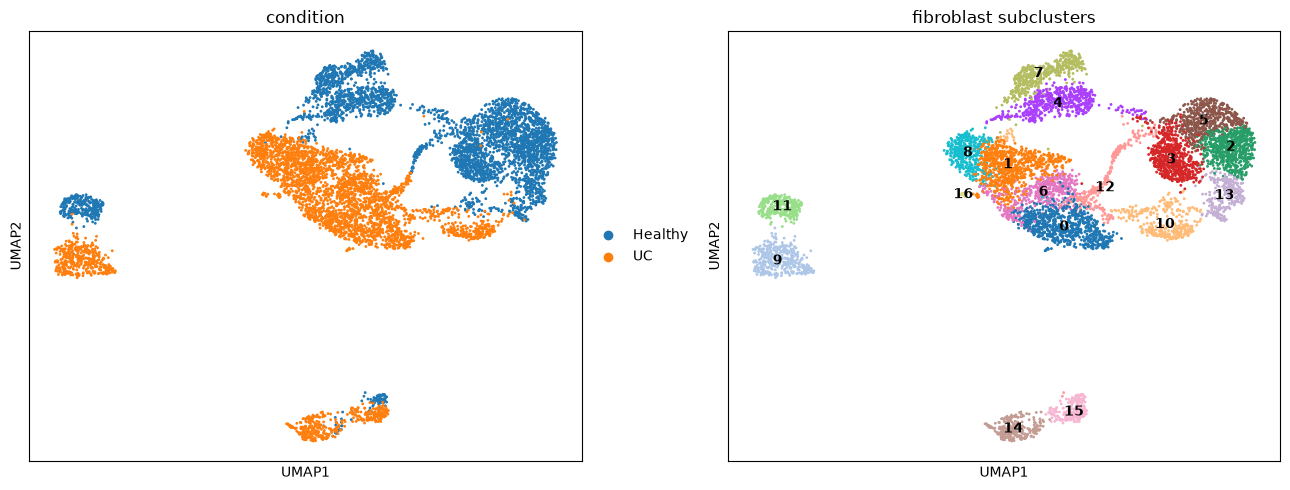

In [3]:
# Re-embed the fibroblast subset at higher resolution
sc.pp.highly_variable_genes(fib, n_top_genes=2000, batch_key="condition")
sc.tl.pca(fib, n_comps=40)
sc.pp.neighbors(fib, n_pcs=30)
sc.tl.umap(fib)
sc.tl.leiden(fib, resolution=1.0, key_added="fib_leiden")
print("fibroblast subclusters:", fib.obs["fib_leiden"].nunique())
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sc.pl.umap(fib, color="condition", ax=axes[0], show=False, title="condition")
sc.pl.umap(fib, color="fib_leiden", ax=axes[1], show=False, title="fibroblast subclusters", legend_loc="on data")
plt.tight_layout(); plt.savefig("../figures/kinchen_fibroblast_umap.png", dpi=130); plt.show()


watch present: ['IL11', 'IL13RA2', 'IL24', 'CHI3L1', 'MMP3', 'MMP10', 'IL6', 'CXCL1', 'CXCL5', 'OSMR', 'SIGIRR', 'IL1R1', 'PDPN', 'CD34', 'ADAMDEC1', 'CCL19', 'COL7A1', 'WNT2B', 'WNT5B']


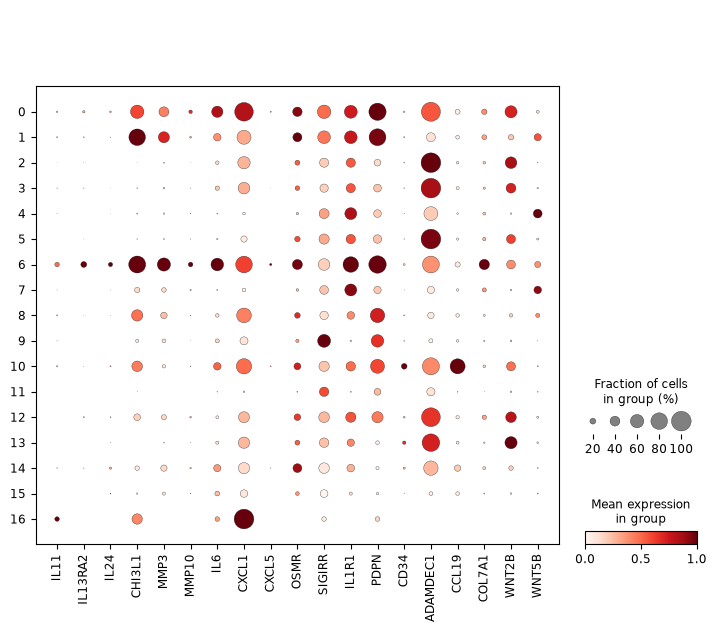

In [4]:
# The replication question: inflammatory-fibroblast markers by subcluster
watch = ["IL11", "IL13RA2", "IL24", "CHI3L1", "MMP3", "MMP10", "IL6", "CXCL1", "CXCL5",
         "OSMR", "SIGIRR", "IL1R1", "PDPN", "CD34", "ADAMDEC1", "CCL19", "COL7A1", "WNT2B", "WNT5B"]
watch = [g for g in watch if g in fib.var_names]
print("watch present:", watch)
sc.pl.dotplot(fib, watch, groupby="fib_leiden", standard_scale="var")


condition   Healthy     UC
fib_leiden                
0             0.000  0.207
1             0.000  0.202
2             0.186  0.000
3             0.171  0.000
4             0.154  0.000
5             0.148  0.001
6             0.000  0.139
7             0.125  0.000
8             0.001  0.111
9             0.001  0.108
10            0.022  0.076
11            0.075  0.001
12            0.029  0.044
13            0.067  0.004
14            0.006  0.066
15            0.016  0.039
16            0.000  0.002


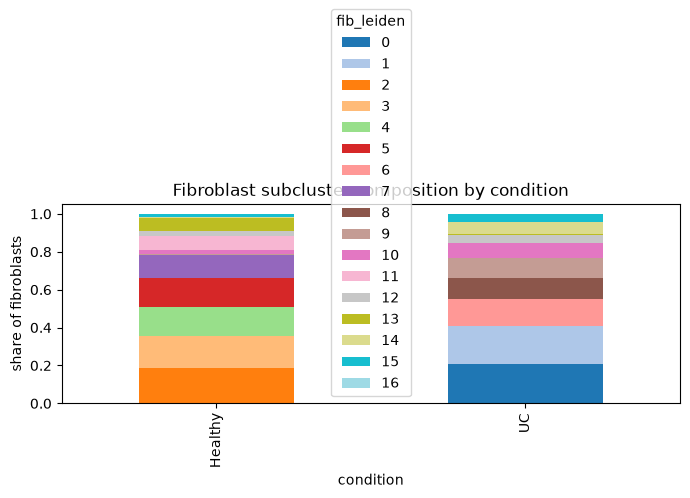

In [5]:
# Abundance readout: subcluster share within fibroblasts, per condition
ct = pd.crosstab(fib.obs["fib_leiden"], fib.obs["condition"], normalize="columns").round(3)
print(ct)
ax = ct.T.plot(kind="bar", stacked=True, figsize=(7, 4), colormap="tab20")
ax.set_ylabel("share of fibroblasts"); ax.set_title("Fibroblast subcluster composition by condition")
plt.tight_layout(); plt.savefig("../figures/kinchen_fibroblast_composition.png", dpi=130); plt.show()


In [6]:
# Inflammatory program score (module 1 gene set) per subcluster x condition
prog = ["IL11", "IL13RA2", "IL24", "CHI3L1", "MMP3", "MMP10", "IL6", "CXCL1", "CXCL5"]
prog = [g for g in prog if g in fib.var_names]
sc.tl.score_genes(fib, prog, score_name="infl_fib_score")
summ = fib.obs.groupby(["fib_leiden", "condition"])["infl_fib_score"].mean().unstack().round(3)
print(summ)
# SIGIRR and OSMR means alongside
for g in ["SIGIRR", "OSMR"]:
    if g in fib.var_names:
        fib.obs[f"_e_{g}"] = np.asarray(fib[:, g].X.todense()).ravel() if sp.issparse(fib.X) else np.asarray(fib[:, g].X).ravel()
        print(g); print(fib.obs.groupby(["fib_leiden", "condition"])[f"_e_{g}"].mean().unstack().round(3))
fib.write(os.path.join(base, "adata_kinchen_fibroblast.h5ad"))
print("saved adata_kinchen_fibroblast.h5ad")


condition   Healthy     UC
fib_leiden                
0               NaN  0.331
1               NaN  0.186
2            -0.170    NaN
3            -0.131  0.195
4            -0.296 -0.292
5            -0.260 -0.135
6            -0.242  0.469
7            -0.223  0.042
8            -0.174  0.037
9            -0.213 -0.185
10           -0.148  0.131
11           -0.248 -0.273
12           -0.281 -0.020
13           -0.172 -0.080
14           -0.232 -0.162
15           -0.268 -0.193
16              NaN  0.315
SIGIRR
condition   Healthy     UC
fib_leiden                
0               NaN  0.575
1               NaN  0.556
2             0.411    NaN
3             0.406  0.000
4             0.485  0.000
5             0.472  0.000
6             0.000  0.406
7             0.425  1.444
8             0.000  0.377
9             0.711  0.849
10            0.393  0.432
11            0.627  0.000
12            0.428  0.461
13            0.438  0.352
14            0.267  0.360
15            0.231  

## Read-out (fill in after running)

- Which subcluster (if any) is IL11/IL13RA2/IL24-high, and is it UC-enriched in
  the composition table? That is the Kinchen replication verdict for the
  inflammatory fibroblast state.
- SIGIRR by subcluster x condition: does the brake weaken in UC fibroblasts?
- Next: notebook 03 — Martin CD load/QC (full circuit replication cohort);
  notebook 04 — human integration; notebook 05 — Kinchen mouse arm.
